In [33]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cuda'

In [ ]:
import numpy as np

dataset = np.load("skull.full.npz", allow_pickle=True, encoding="latin1")
dataset["train"][0].shape

(64, 3)

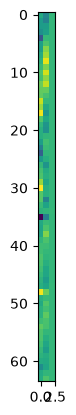

In [35]:
import matplotlib.pyplot as plt

plt.imshow(dataset["train"][0])

In [41]:
import cairocffi as cairo
import numpy as np


def vector_to_raster(
    vector_images,
    side=28,
    line_diameter=16,
    padding=16,
    bg_color=(0, 0, 0),
    fg_color=(1, 1, 1),
):
    """
    padding and line_diameter are relative to the original 256x256 image.
    """

    original_side = 256.0

    surface = cairo.ImageSurface(cairo.FORMAT_ARGB32, side, side)
    ctx = cairo.Context(surface)
    ctx.set_antialias(cairo.ANTIALIAS_BEST)
    ctx.set_line_cap(cairo.LINE_CAP_ROUND)
    ctx.set_line_join(cairo.LINE_JOIN_ROUND)
    ctx.set_line_width(line_diameter)

    # scale to match the new size
    # add padding at the edges for the line_diameter
    # and add additional padding to account for antialiasing
    total_padding = padding * 2.0 + line_diameter
    new_scale = float(side) / float(original_side + total_padding)
    ctx.scale(new_scale, new_scale)
    ctx.translate(total_padding / 2.0, total_padding / 2.0)

    raster_images = []
    for vector_image in vector_images:
        # clear background
        ctx.set_source_rgb(*bg_color)
        ctx.paint()

        bbox = np.hstack(vector_image).max(axis=1)
        offset = ((original_side, original_side) - bbox) / 2.0
        offset = offset.reshape(-1, 1)
        centered = [stroke + offset for stroke in vector_image]

        # draw strokes, this is the most cpu-intensive part
        ctx.set_source_rgb(*fg_color)
        for xv, yv in centered:
            ctx.move_to(xv[0], yv[0])
            for x, y in zip(xv, yv):
                ctx.line_to(x, y)
            ctx.stroke()

        data = surface.get_data()
        raster_image = np.copy(np.asarray(data)[::4])
        raster_images.append(raster_image)

    return raster_images


def stroke3_to_strokes(drawing):
    drawing = drawing.astype(np.float32)
    xy = np.cumsum(drawing[:, :2], axis=0)
    xy -= xy.min(axis=0)
    cuts = np.where(drawing[:, 2] == 1)[0] + 1
    parts = np.split(xy, cuts)
    return [p.T for p in parts if len(p) > 0]

In [ ]:
test = dataset["test"]
side = 64
vec = [stroke3_to_strokes(d) for d in test]
imgs = vector_to_raster(vec, side=side)
test_imgs = np.stack(imgs).reshape(-1, side, side)

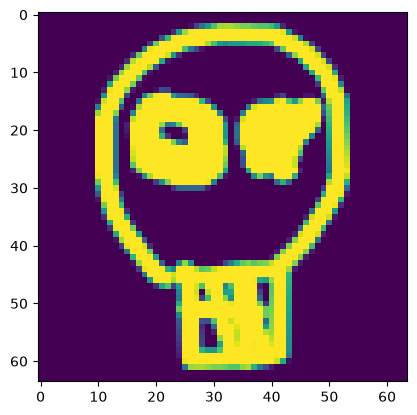

In [45]:
plt.imshow(imgs[0])